In [ ]:
import pandas as pd
f=open("myfile.txt", "r", encoding="utf-8")

In [ ]:
f = io.StringIO("some initial text data")

In [ ]:
f = io.BytesIO(b"some initial binary data: \x00\x01")

In [ ]:
with open("myfile.txt", "w", encoding="utf-8") as f:
  f.write("Hello, this is myfile.txt")

print("myfile.txt 파일이 성공적으로 생성되었습니다.")

myfile.txt 파일이 성공적으로 생성되었습니다.


In [ ]:
%whos

Variable   Type             Data/Info
-------------------------------------
contents   str              First line.\nSecond line.\n
f          TextIOWrapper    <_io.TextIOWrapper name='<...>ode='w' encoding='utf-8'>
io         module           <module 'io' (frozen)>
output     StringIO         <_io.StringIO object at 0x7ef6e1970700>
pd         module           <module 'pandas' from '/u<...>ages/pandas/__init__.py'>


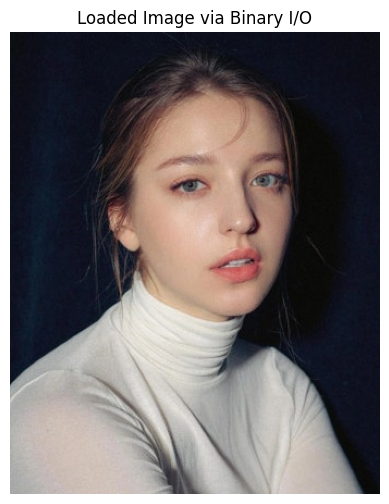

In [ ]:
import io
import matplotlib.pyplot as plt
import requests
from PIL import Image

url = "https://search.pstatic.net/sunny/?src=https%3A%2F%2Fi.namu.wiki%2Fi%2FGs7Hu3j29pCs4kPfoC9r03AYliCriOES4aqTvGsR3PWbFaHoKkQX5OHQYCo-Ac8zLWtidGc6Cd3fgFKHy_9gZA.webp&type=a340"

headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36"
}

response = requests.get(url, headers=headers)
response.raise_for_status()

image_bytes = io.BytesIO(response.content)

image = Image.open(image_bytes)

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off")  # 축 표시 안 함
plt.title("Loaded Image via Binary I/O")
plt.show()

In [ ]:
pip install faker pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 44.3 MB/s eta 0:00:00


In [ ]:
import sqlite3
from faker import Faker
import pandas as pd

In [ ]:
fake = Faker('ru_RU') # 한국어 데이터 생성
Faker.seed(42)

csv_filename = "users_sample.csv"
sample_data = []

for i in range(1, 11):
    sample_data.append({
        "name": fake.name(),
        "email": fake.email(),
        "age": fake.random_int(min=20, max=60),
        "job": fake.job()
    })

df_init = pd.DataFrame(sample_data)
df_init.to_csv(csv_filename, index=False, encoding='utf-8-sig')
print(f"1. Faker로 샘플 CSV 파일 '{csv_filename}' 생성 완료!\n")

1. Faker로 샘플 CSV 파일 'users_sample.csv' 생성 완료!



In [ ]:
conn = sqlite3.connect("practice.db")
cursor = conn.cursor()

cursor.execute("""
CREATE TABLE IF NOT EXISTS users (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    name TEXT NOT NULL,
    email TEXT NOT NULL,
    age INTEGER,
    job TEXT
)
""")
conn.commit()

In [ ]:
df_csv = pd.read_csv(csv_filename, encoding='utf-8-sig')

In [ ]:
df_csv.to_sql('users', conn, if_exists='append', index=False)
print("2. CSV 데이터를 SQLite 'users' 테이블에 저장 완료!\n")

2. CSV 데이터를 SQLite 'users' 테이블에 저장 완료!



In [ ]:
def create_user(name, email, age, job):
    sql = "INSERT INTO users (name, email, age, job) VALUES (?, ?, ?, ?)"
    cursor.execute(sql, (name, email, age, job))
    conn.commit()
    print(f"--- [CREATE] '{name}' 사용자 추가 완료 ---")

# [UPDATE] 사용자 정보 수정
def update_user_job(user_id, new_job):
    sql = "UPDATE users SET job = ? WHERE id = ?"
    cursor.execute(sql, (new_job, user_id))
    conn.commit()
    print(f"--- [UPDATE] ID {user_id}의 직업을 '{new_job}'(으)로 변경 완료 ---")

# [DELETE] 사용자 삭제
def delete_user(user_id):
    sql = "DELETE FROM users WHERE id = ?"
    cursor.execute(sql, (user_id,))
    conn.commit()
    print(f"--- [DELETE] ID {user_id} 사용자 삭제 완료 ---")

In [ ]:
if __name__ == "__main__":
  init_db()
load_csv_to_db(csv_filename)

read_all_users()
create_user("홍길동", "gildong@example.com", 30, "백엔드 개발자")
read_all_users()
update_user_job(1, "데이터 엔지니어")
read_all_users()
delete_user(2)
read_all_users()

NameError: name 'init_db' is not defined

In [ ]:
conn.close()
print("실습 완료 및 DB 연결 종료.")

실습 완료 및 DB 연결 종료.


In [ ]:
import pandas as pd
from faker import Faker

# 한국어 Faker 객체 생성
fake = Faker("ru_RU")

# 난수 시드 고정 (매번 동일한 무작위 데이터를 얻고 싶다면 설정, 원치 않으면 삭제 가능)
Faker.seed(42)

# 100개의 예제 데이터 생성
data_count = 100
sample_data = []

for i in range(1, data_count + 1):
    sample_data.append(
        {
            "id": i,
            "name": fake.name(),
            "email": fake.email(),
            "phone_number": fake.phone_number(),
            "address": fake.address(),
            "company": fake.company(),
            "job": fake.job(),
            "birthdate": fake.date_of_birth(minimum_age=20, maximum_age=60).strftime("%Y-%m-%d"),
            "created_at": fake.date_time_this_year().strftime("%Y-%m-%d %H:%M:%S"),
        }
    )

# Pandas DataFrame으로 변환
df = pd.DataFrame(sample_data)

# CSV 파일로 저장 (한글 깨짐 방지를 위해 utf-8-sig 사용)
csv_filename = "faker_sample_100.csv"
df.to_csv(csv_filename, index=False, encoding="utf-8-sig")

# 결과 확인 (상위 5개 출력)
print(f"총 {len(df)}개의 데이터가 성공적으로 생성되어 '{csv_filename}'에 저장되었습니다.\n")
print(df.head())

총 100개의 데이터가 성공적으로 생성되어 'faker_sample_100.csv'에 저장되었습니다.

   id                               name                         email  \
0   1             Козлова Ирина Ефимовна  visheslavzinovev@example.org   
1   2         Белякова Варвара Мироновна   zhdanovkuprijan@example.net   
2   3  Елизавета Антоновна Константинова           oleg_41@example.org   
3   4      Матвей Брониславович Анисимов          dveselov@example.org   
4   5          Еремей Германович Кулаков          nifont57@example.net   

        phone_number                                            address  \
0   8 (196) 001-3389       клх Усинск, алл. Рылеева, д. 1 к. 66, 235116   
1        85931034131            с. Ноглики, наб. Крылова, д. 24, 832764   
2        85376724238  д. Петрозаводск, алл. Придорожная, д. 2/1 к. 7...   
3       +78281489325     д. Муравленко, ул. Боровая, д. 5 к. 40, 171822   
4  8 (133) 150-98-39        г. Яхрома, алл. Профсоюзная, д. 951, 473829   

                                   company    

In [ ]:
import sqlite3
con = sqlite3.connect("tutorial.db")

In [ ]:
cur = con.cursor()

In [ ]:
cur.execute("CREATE TABLE movie(title, year, score)")

In [ ]:
res = cur.execute("SELECT name FROM sqlite_master")
res.fetchone()

In [ ]:
res = cur.execute("SELECT name FROM sqlite_master WHERE name='spam'")
res.fetchone() is None

True

In [ ]:
cur.execute("""
    INSERT INTO movie VALUES
        ('Monty Python and the Holy Grail', 1975, 8.2),
        ('And Now for Something Completely Different', 1971, 7.5)
""")

OperationalError: no such table: movie

In [ ]:
con.commit()

In [ ]:
res = cur.execute("SELECT score FROM movie")
res.fetchall()

OperationalError: no such table: movie

In [ ]:
data = [
    ("Monty Python Live at the Hollywood Bowl", 1982, 7.9),
    ("Monty Python's The Meaning of Life", 1983, 7.5),
    ("Monty Python's Life of Brian", 1979, 8.0),
]
cur.executemany("INSERT INTO movie VALUES(?, ?, ?)", data)
con.commit()  # Remember to commit the transaction after executing INSERT.

OperationalError: no such table: movie

In [ ]:
import sqlite3
import pandas as pd
from faker import Faker

# ---------------------------------------------------------
# 1. Faker로 10개 예제 데이터 생성 후 CSV 저장
# ---------------------------------------------------------
fake = Faker("ko_KR")
Faker.seed(42)

csv_filename = "users_sample.csv"
sample_data = []

for i in range(1, 11):
    sample_data.append(
        {
            "name": fake.name(),
            "email": fake.email(),
            "age": fake.random_int(min=20, max=60),
            "job": fake.job(),
        }
    )

df_init = pd.DataFrame(sample_data)
df_init.to_csv(csv_filename, index=False, encoding="utf-8-sig")
print(f"1. Faker로 '{csv_filename}' 샘플 파일 생성 완료!\n")


# ---------------------------------------------------------
# 2. CRUD 함수 정의 (with 구문 사용)
# ---------------------------------------------------------
DB_NAME = "practice.db"


def init_db():
    """테이블 생성"""
    with sqlite3.connect(DB_NAME) as conn:
        cursor = conn.cursor()
        cursor.execute(
            """
        CREATE TABLE IF NOT EXISTS users (
            id INTEGER PRIMARY KEY AUTOINCREMENT,
            name TEXT NOT NULL,
            email TEXT NOT NULL,
            age INTEGER,
            job TEXT
        )
        """
        )
    print("2. DB 및 'users' 테이블 생성 완료!\n")


def load_csv_to_db(filename):
    """CSV 파일 읽어서 DB에 일괄 저장 (CREATE)"""
    df = pd.read_csv(filename, encoding="utf-8-sig")
    with sqlite3.connect(DB_NAME) as conn:
        # pandas to_sql도 conn을 인자로 받아 with 구문 내에서 실행 가능
        df.to_sql("users", conn, if_exists="append", index=False)
    print("3. CSV 데이터를 SQLite DB에 저장 완료!\n")


def read_all_users():
    """[READ] 전체 사용자 조회"""
    with sqlite3.connect(DB_NAME) as conn:
        cursor = conn.cursor()
        cursor.execute("SELECT * FROM users")
        rows = cursor.fetchall()

    print("--- [READ] 현재 users 테이블 데이터 ---")
    for row in rows:
        print(row)
    print("---------------------------------------\n")


def create_user(name, email, age, job):
    """[CREATE] 신규 사용자 추가"""
    with sqlite3.connect(DB_NAME) as conn:
        cursor = conn.cursor()
        sql = "INSERT INTO users (name, email, age, job) VALUES (?, ?, ?, ?)"
        cursor.execute(sql, (name, email, age, job))
        # with 구문 종료 시 자동 commit 완료됨
    print(f"--- [CREATE] '{name}' 사용자 추가 완료 ---")


def update_user_job(user_id, new_job):
    """[UPDATE] 사용자 직업 변경"""
    with sqlite3.connect(DB_NAME) as conn:
        cursor = conn.cursor()
        sql = "UPDATE users SET job = ? WHERE id = ?"
        cursor.execute(sql, (new_job, user_id))
    print(f"--- [UPDATE] ID {user_id}의 직업을 '{new_job}'(으)로 변경 완료 ---")


def delete_user(user_id):
    """[DELETE] 사용자 삭제"""
    with sqlite3.connect(DB_NAME) as conn:
        cursor = conn.cursor()
        sql = "DELETE FROM users WHERE id = ?"
        cursor.execute(sql, (user_id,))
    print(f"--- [DELETE] ID {user_id} 사용자 삭제 완료 ---")


# ---------------------------------------------------------
# 3. 실습 실행
# ---------------------------------------------------------
if __name__ == "__main__":
    # 테이블 초기화 및 CSV 데이터 삽입
    init_db()
    load_csv_to_db(csv_filename)

    # 1) [READ] 초기 데이터 확인
    read_all_users()

    # 2) [CREATE] 사용자 추가
    create_user("홍길동", "gildong@example.com", 30, "백엔드 개발자")
    read_all_users()

    # 3) [UPDATE] 1번 ID 사용자 정보 수정
    update_user_job(1, "데이터 엔지니어")
    read_all_users()

    # 4) [DELETE] 2번 ID 사용자 삭제
    delete_user(2)
    read_all_users()

    print("모든 SQLite CRUD 실습이 성공적으로 완료되었습니다.")

1. Faker로 'users_sample.csv' 샘플 파일 생성 완료!

2. DB 및 'users' 테이블 생성 완료!

3. CSV 데이터를 SQLite DB에 저장 완료!

--- [READ] 현재 users 테이블 데이터 ---
(1, '김수민', 'seongmingim@example.net', 54, '토목공학 기술자')
(2, '김미숙', 'migyeonggim@example.org', 54, '피부미용 및 체형관리사')
(3, '최준서', 'gweonseonghyeon@example.com', 41, '기타 기술영업 및 중개 관련 종사자')
(4, '성성진', 'ijongsu@example.com', 58, '조사 전문가')
(5, '서옥자', 'sgim@example.net', 59, '무역 사무원')
(6, '한경희', 'eungyeongmin@example.org', 26, '금융관련 사무원')
(7, '윤성호', 'jeonghun41@example.net', 60, '응급구조사')
(8, '김예은', 'hyeonji83@example.net', 40, '종이제품 생산기 조작원')
(9, '김경희', 'junho13@example.net', 40, '컴퓨터 강사')
(10, '이하은', 'igim@example.org', 55, '의복/가죽 및 모피 수선원')
(11, 'Козлова Ирина Ефимовна', 'visheslavzinovev@example.org', 54, 'Гепатолог')
(12, 'Морозова Алевтина Богдановна', 'igorseleznev@example.net', 21, 'Корректировщик')
(13, 'Филатова София Николаевна', 'prohorsafonov@example.com', 20, 'Инженер-электрик')
(14, 'Александрова Ирина Владиславовна', 'martinorlov@example.org', 44, 'Го

In [ ]:
r = requests.get('https://api.github.com/user', auth=('user', 'pass'))
r.status_code

401

In [ ]:
r.headers['content-type']

'application/json; charset=utf-8'

In [ ]:
r.encoding

'utf-8'

In [ ]:
r.text

'{"message":"Requires authentication","documentation_url":"https://docs.github.com/rest/users/users#get-the-authenticated-user","status":"401"}'

In [ ]:
r.json()

{'message': 'Requires authentication',
 'documentation_url': 'https://docs.github.com/rest/users/users#get-the-authenticated-user',
 'status': '401'}

In [ ]:
import requests

In [ ]:
r = requests.get('https://api.github.com/events')

In [ ]:
r = requests.post('https://httpbin.org/post', data={'key': 'value'})

In [ ]:
r = requests.put('https://httpbin.org/put', data={'key': 'value'})
r = requests.delete('https://httpbin.org/delete')
r = requests.head('https://httpbin.org/get')
r = requests.options('https://httpbin.org/get')

In [ ]:
payload = {'key1': 'value1', 'key2': 'value2'}
r = requests.get('https://httpbin.org/get', params=payload)

In [ ]:
print(r.url)

https://httpbin.org/get?key1=value1&key2=value2


In [ ]:
payload = {'key1': 'value1', 'key2': ['value2', 'value3']}

In [ ]:
r = requests.get('https://httpbin.org/get', params=payload)
print(r.url)


https://httpbin.org/get?key1=value1&key2=value2&key2=value3


In [ ]:
r = requests.get('https://api.github.com/events')
r.text

'[{"id":"24149662031","type":"CreateEvent","actor":{"id":32994011,"login":"ytchou","display_login":"ytchou","gravatar_id":"","url":"https://api.github.com/users/ytchou","avatar_url":"https://avatars.githubusercontent.com/u/32994011?"},"repo":{"id":1230632509,"name":"ytchou/Formoria","url":"https://api.github.com/repos/ytchou/Formoria"},"payload":{"ref":"claude/funny-albattani-fvbamq","ref_type":"branch","full_ref":"refs/heads/claude/funny-albattani-fvbamq","master_branch":"main","description":"Taiwanese brand discovery and curation — find, compare and support brands that actually make things in Taiwan.","pusher_type":"user"},"public":true,"created_at":"2026-10-14T21:01:22Z"},{"id":"24149662125","type":"CreateEvent","actor":{"id":206951365,"login":"cursor[bot]","display_login":"cursor","gravatar_id":"","url":"https://api.github.com/users/cursor[bot]","avatar_url":"https://avatars.githubusercontent.com/u/206951365?"},"repo":{"id":1420802388,"name":"WittCsharp/xiaozhi-esp32","url":"https:

In [ ]:
r.encoding

'utf-8'

In [ ]:
r.encoding = 'ISO-8859-1'

In [ ]:
r.content

b'[{"id":"24149662031","type":"CreateEvent","actor":{"id":32994011,"login":"ytchou","display_login":"ytchou","gravatar_id":"","url":"https://api.github.com/users/ytchou","avatar_url":"https://avatars.githubusercontent.com/u/32994011?"},"repo":{"id":1230632509,"name":"ytchou/Formoria","url":"https://api.github.com/repos/ytchou/Formoria"},"payload":{"ref":"claude/funny-albattani-fvbamq","ref_type":"branch","full_ref":"refs/heads/claude/funny-albattani-fvbamq","master_branch":"main","description":"Taiwanese brand discovery and curation \xe2\x80\x94 find, compare and support brands that actually make things in Taiwan.","pusher_type":"user"},"public":true,"created_at":"2026-10-14T21:01:22Z"},{"id":"24149662125","type":"CreateEvent","actor":{"id":206951365,"login":"cursor[bot]","display_login":"cursor","gravatar_id":"","url":"https://api.github.com/users/cursor[bot]","avatar_url":"https://avatars.githubusercontent.com/u/206951365?"},"repo":{"id":1420802388,"name":"WittCsharp/xiaozhi-esp32","

In [ ]:
from PIL import Image
from io import BytesIO

In [ ]:
#i = Image.open(BytesIO(r.content))

In [ ]:
r = requests.get('https://api.github.com/events')
r.json()

[{'id': '24149789506',
  'type': 'PushEvent',
  'actor': {'id': 336566493,
   'login': 'abdelkader-baggag',
   'display_login': 'abdelkader-baggag',
   'gravatar_id': '',
   'url': 'https://api.github.com/users/abdelkader-baggag',
   'avatar_url': 'https://avatars.githubusercontent.com/u/336566493?'},
  'repo': {'id': 1418831006,
   'name': 'abdelkader-baggag/LENS',
   'url': 'https://api.github.com/repos/abdelkader-baggag/LENS'},
  'payload': {'repository_id': 1418831006,
   'push_id': 46477259692,
   'ref': 'refs/heads/main',
   'head': 'de22e1f4fcc12cde033cee91cab054e904b50f4b',
   'before': '205b03b88a5a9843e163899e5df76332264cf98d'},
  'public': True,
  'created_at': '2026-10-14T14:05:33Z'},
 {'id': '24149788946',
  'type': 'PushEvent',
  'actor': {'id': 14028309,
   'login': 'jpdrecourt',
   'display_login': 'jpdrecourt',
   'gravatar_id': '',
   'url': 'https://api.github.com/users/jpdrecourt',
   'avatar_url': 'https://avatars.githubusercontent.com/u/14028309?'},
  'repo': {'id

In [ ]:
r = requests.get('https://api.github.com/events', stream=True)

In [ ]:
r.raw

In [ ]:
r.raw.read(10)

b'\x1f\x8b\x08\x00\x00\x00\x00\x00\x00\x03'

_IncompleteInputError: incomplete input (1964935432.py, line 1)

In [ ]:
'''
{
  "args": {},
  "headers": {
    "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,image/avif,image/webp,image/apng,*/*;q=0.8,application/signed-exchange;v=b3;q=0.7",
    "Accept-Encoding": "gzip, deflate",
    "Accept-Language": "ko-KR,ko;q=0.9,en-US;q=0.8,en;q=0.7",
    "Host": "httpbin.org",
    "Upgrade-Insecure-Requests": "1",
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/115.0.0.0 Safari/537.36",
    "X-Amzn-Trace-Id": "Root=1-64d6350b-4d8c7710021da0ab4ccabacc"
  },
  "origin": "112.169.221.81",
  "url": "http://httpbin.org/get"
}
'''

'\n{\n  "args": {},\n  "headers": {\n    "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,image/avif,image/webp,image/apng,*/*;q=0.8,application/signed-exchange;v=b3;q=0.7",\n    "Accept-Encoding": "gzip, deflate",\n    "Accept-Language": "ko-KR,ko;q=0.9,en-US;q=0.8,en;q=0.7",\n    "Host": "httpbin.org",\n    "Upgrade-Insecure-Requests": "1",\n    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/115.0.0.0 Safari/537.36",\n    "X-Amzn-Trace-Id": "Root=1-64d6350b-4d8c7710021da0ab4ccabacc"\n  },\n  "origin": "112.169.221.81",\n  "url": "http://httpbin.org/get"\n}\n'

In [ ]:


import requests
r = requests.get('https://httpbin.org/')
print(r)

<Response [200]>


In [ ]:
print(r.text)

<!DOCTYPE html>
<html lang="en">

<head>
    <meta charset="UTF-8">
    <title>httpbin.org</title>
    <link href="https://fonts.googleapis.com/css?family=Open+Sans:400,700|Source+Code+Pro:300,600|Titillium+Web:400,600,700"
        rel="stylesheet">
    <link rel="stylesheet" type="text/css" href="/flasgger_static/swagger-ui.css">
    <link rel="icon" type="image/png" href="/static/favicon.ico" sizes="64x64 32x32 16x16" />
    <style>
        html {
            box-sizing: border-box;
            overflow: -moz-scrollbars-vertical;
            overflow-y: scroll;
        }

        *,
        *:before,
        *:after {
            box-sizing: inherit;
        }

        body {
            margin: 0;
            background: #fafafa;
        }
    </style>
</head>

<body>
    <a href="https://github.com/requests/httpbin" class="github-corner" aria-label="View source on Github">
        <svg width="80" height="80" viewBox="0 0 250 250" style="fill:#151513; color:#fff; position: absolute;

In [ ]:
url = 'https://httpbin.org/get'

In [ ]:
r = requests.get(url)
print(r.text)


{
  "args": {}, 
  "headers": {
    "Accept": "*/*", 
    "Accept-Encoding": "gzip, deflate, br, zstd", 
    "Host": "httpbin.org", 
    "User-Agent": "python-requests/2.32.4", 
    "X-Amzn-Trace-Id": "Root=1-6ad189a7-548af0d415fe016454d9168e"
  }, 
  "origin": "34.178.157.171", 
  "url": "https://httpbin.org/get"
}

